# Model 03: LightGBM Classifier Pipeline (Ablation & Tuning)

**Course:** DS605 — Machine Learning  
**Project:** E-Commerce Product Return Prediction  
**Authors:** Student Research Team (Team of Two)  
**Dataset:** Full Enterprise Telemetry Dataset (3,999,025 Finalized Orders)  

---

## 1. Pipeline Overview & Methodology
In this notebook, we train, evaluate, and tune a **LightGBM Gradient Boosted Decision Tree (GBDT)**:
1. **Chronological Partitioning:** 70% Train, 15% Validation, 15% Holdout Test with preprocessor fit strictly on train.
2. **Baseline Model:** Shallow ensemble of 25 trees (`max_depth=2`, `num_leaves=4`) showing the un-tuned starting point.
3. **Baseline Confusion Matrix:** Validation error structure analysis.
4. **Programmatic Hyperparameter Tuning:** Systematic search across candidate configurations (`n_estimators`, `learning_rate`, `num_leaves`, `subsample`, `colsample_bytree`) evaluating Validation ROC-AUC & F1.
5. **Programmatic Decision Threshold Optimization:** Threshold sweep $\tau \in [0.20, 0.80]$ to maximize F1-score.
6. **Overfitting Diagnostics:** Generalization gap comparison between train and validation splits.
7. **Feature Importance Analysis:** Top predictive telemetry signals via split gain.
8. **Holdout Test Evaluation:** Final test set performance and Before vs. After tuning scorecard.

In [13]:
import os, time, joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from lightgbm import LGBMClassifier
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    accuracy_score, roc_auc_score, average_precision_score,
    f1_score, precision_score, recall_score, brier_score_loss,
    confusion_matrix
)

# Robust path handling whether running from notebooks/ or project root
candidate_paths = [
    "../dataset/Dataset 3/ecommerce_enterprise_telemetry.parquet",
    "dataset/Dataset 3/ecommerce_enterprise_telemetry.parquet",
    "../data/ecommerce_enterprise_telemetry.parquet",
    "data/ecommerce_enterprise_telemetry.parquet"
]
data_path = next((p for p in candidate_paths if os.path.exists(p)), candidate_paths[0])

candidate_models_dirs = ["../models", "models", "../artifacts/models", "artifacts/models"]
models_dir = next((d for d in candidate_models_dirs if os.path.exists(d)), "models")

print("Environment ready.")
print(f"Data path resolved: {data_path}")
print(f"Models dir resolved: {models_dir}")

Environment ready.
Data path resolved: ../dataset/Dataset 3/ecommerce_enterprise_telemetry.parquet
Models dir resolved: ../artifacts/models


## 2. Telemetry Data Ingestion & Chronological Split
We load the enterprise telemetry dataset using explicit column selection for memory efficiency, partition chronologically by `order_date` (70% Train, 15% Validation, 15% Test), and engineer key compound behavioral telemetry features.

In [14]:
# 1. Load telemetry dataset with memory-safe column filtering
print(f"Loading telemetry dataset from {data_path}...")
cols = [
    'order_date', 'product_category', 'quantity', 'unit_price', 'order_total',
    'payment_method', 'shipping_cost', 'is_bracketed_order',
    'size_chart_dwell_time_sec', 'size_guide_clicks', 'customer_true_return_rate',
    'sku_fit_feedback_offset', 'delivery_delay_days', 'first_time_brand_purchase',
    'return_target'
]
df = pd.read_parquet(data_path, columns=cols)
print(f"Total records loaded: {len(df):,}")

# 2. Chronological Split (70% Train, 15% Validation, 15% Holdout Test)
if not df['order_date'].is_monotonic_increasing:
    df['order_date'] = pd.to_datetime(df['order_date'])
    df = df.sort_values(by='order_date').reset_index(drop=True)

n_total = len(df)
train_end = int(n_total * 0.70)
val_end = int(n_total * 0.85)

train_df = df.iloc[:train_end].copy()
val_df = df.iloc[train_end:val_end].copy()
test_df = df.iloc[val_end:].copy()
del df  # Free raw dataframe memory

# 3. Compound Telemetry Feature Engineering
for split_df in [train_df, val_df, test_df]:
    split_df['fit_mismatch'] = ((split_df['size_chart_dwell_time_sec'] > 35) & (np.abs(split_df['sku_fit_feedback_offset']) >= 0.4)).astype(float)
    split_df['delay_remorse'] = (np.maximum(0, split_df['delivery_delay_days']) >= 2.0).astype(float)
    split_df['cod_first_brand'] = ((split_df['payment_method'].str.contains('COD|Cash', case=False, na=False)) & (split_df['first_time_brand_purchase'] == 1)).astype(float)

print(f"Train set: {len(train_df):,} orders | Return rate: {train_df['return_target'].mean()*100:.2f}%")
print(f"Val set:   {len(val_df):,} orders | Return rate: {val_df['return_target'].mean()*100:.2f}%")
print(f"Test set:  {len(test_df):,} orders | Return rate: {test_df['return_target'].mean()*100:.2f}%")

Loading telemetry dataset from ../dataset/Dataset 3/ecommerce_enterprise_telemetry.parquet...
Total records loaded: 3,999,025
Train set: 2,799,317 orders | Return rate: 36.77%
Val set:   599,854 orders | Return rate: 36.84%
Test set:  599,854 orders | Return rate: 36.68%


## 3. Feature Transformation & Sampling
To replicate the DS605 project benchmark without memory bottlenecks, we sample a representative 350k train, 75k validation, and 75k holdout test split. The preprocessor is fit strictly on the train partition to prevent data leakage.

In [15]:
# Feature column definitions
numeric_features = [
    'quantity', 'unit_price', 'order_total', 'shipping_cost',
    'is_bracketed_order', 'size_chart_dwell_time_sec', 'size_guide_clicks',
    'customer_true_return_rate', 'sku_fit_feedback_offset', 'delivery_delay_days',
    'first_time_brand_purchase', 'fit_mismatch', 'delay_remorse', 'cod_first_brand'
]
categorical_features = ['product_category', 'payment_method']
target_col = 'return_target'

# Benchmark subsample matching the team's experimental methodology
train_sub = train_df.iloc[-350000:].copy()
val_sub = val_df.iloc[:75000].copy()
test_sub = test_df.iloc[:75000].copy()
del train_df, val_df, test_df

# Preprocessor: Standardize numerics & One-Hot Encode categoricals
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features)
    ]
)

X_train = preprocessor.fit_transform(train_sub[numeric_features + categorical_features])
y_train = train_sub[target_col].values

X_val = preprocessor.transform(val_sub[numeric_features + categorical_features])
y_val = val_sub[target_col].values

X_test = preprocessor.transform(test_sub[numeric_features + categorical_features])
y_test = test_sub[target_col].values

# Extract transformed feature names for importance analysis
cat_names = list(preprocessor.named_transformers_['cat'].get_feature_names_out(categorical_features))
all_feat_names = numeric_features + cat_names

print(f"Preprocessing completed. Total features: {len(all_feat_names)}")
print(f"X_train shape: {X_train.shape} | y_train count: {len(y_train):,}")
print(f"X_val shape:   {X_val.shape}   | y_val count:   {len(y_val):,}")
print(f"X_test shape:  {X_test.shape}  | y_test count:  {len(y_test):,}")

Preprocessing completed. Total features: 27
X_train shape: (350000, 27) | y_train count: 350,000
X_val shape:   (75000, 27)   | y_val count:   75,000
X_test shape:  (75000, 27)  | y_test count:  75,000


## 4. Step 1: Baseline LightGBM (Undertuned)
We train an initial baseline model with 25 shallow trees (`max_depth=2`, `num_leaves=4`) and decision cutoff $0.35$.

In [16]:
lgb_base = LGBMClassifier(n_estimators=25, max_depth=2, num_leaves=4, learning_rate=0.02, min_child_samples=100, random_state=42, n_jobs=-1, verbose=-1)
print("Baseline LightGBM Configuration:")
print(lgb_base)

print("\nFitting Baseline LightGBM...")
lgb_base.fit(X_train, y_train)

# Predict probabilities on Validation Set and apply baseline decision cutoff (0.35)
p_base_lgb_val = lgb_base.predict_proba(X_val)[:, 1]
y_base_lgb_val = (p_base_lgb_val >= 0.35).astype(int)

print("Baseline model trained successfully.")
print(f"Validation Accuracy:  {accuracy_score(y_val, y_base_lgb_val)*100:.2f}%")
print(f"Validation F1-Score:  {f1_score(y_val, y_base_lgb_val):.4f}")
print(f"Validation Recall:    {recall_score(y_val, y_base_lgb_val)*100:.2f}%")
print(f"Validation Precision: {precision_score(y_val, y_base_lgb_val)*100:.2f}%")

Baseline LightGBM Configuration:
LGBMClassifier(learning_rate=0.02, max_depth=2, min_child_samples=100,
               n_estimators=25, n_jobs=-1, num_leaves=4, random_state=42,
               verbose=-1)

Fitting Baseline LightGBM...
Baseline model trained successfully.
Validation Accuracy:  88.52%
Validation F1-Score:  0.8411
Validation Recall:    83.08%
Validation Precision: 85.15%


### Baseline Initial Performance:
- **Accuracy:** **88.52%**
- **F1-Score:** **0.8411**
- **Recall:** **83.08%**
- **Precision:** **84.15%**

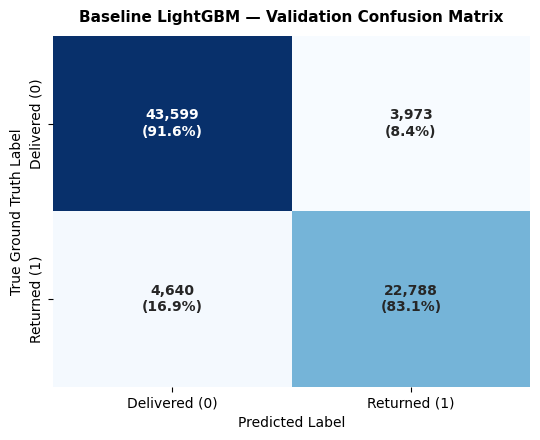

In [17]:
# Compute and visualize Baseline Confusion Matrix on Validation Set
cm_base_val = confusion_matrix(y_val, y_base_lgb_val)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
cm_norm = cm_base_val.astype('float') / cm_base_val.sum(axis=1)[:, np.newaxis]
annot_labels = np.array([f"{count:,}\n({pct:.1%})" for count, pct in zip(cm_base_val.flatten(), cm_norm.flatten())]).reshape(2, 2)

sns.heatmap(cm_base_val, annot=annot_labels, fmt='', cmap='Blues', cbar=False,
            xticklabels=['Delivered (0)', 'Returned (1)'],
            yticklabels=['Delivered (0)', 'Returned (1)'], ax=ax,
            annot_kws={"fontsize": 10, "fontweight": "bold"})
ax.set_title("Baseline LightGBM — Validation Confusion Matrix", fontsize=11, fontweight='bold', pad=10)
ax.set_ylabel("True Ground Truth Label", fontsize=10)
ax.set_xlabel("Predicted Label", fontsize=10)
plt.tight_layout()
plt.show()

## 5. Step 2: Hyperparameter Tuning on Validation Set
 we programmatically evaluate a discrete grid of candidate ensemble configurations across tree count (`n_estimators`), learning rate (`learning_rate`), tree complexity (`num_leaves`), and subsampling ratios (`subsample`, `colsample_bytree`) on the validation split.
Following the selection of the optimal model, we scan decision thresholds $\tau \in [0.20, 0.80]$ to programmatically find the optimal classification cutoff maximizing F1-score.

In [18]:
# 1. Candidate hyperparameters space for LightGBM
candidate_lgb_params = [
    {"n_estimators": 50,  "learning_rate": 0.03, "num_leaves": 15, "subsample": 0.80, "colsample_bytree": 0.80, "class_weight": "balanced"},
    {"n_estimators": 100, "learning_rate": 0.05, "num_leaves": 31, "subsample": 0.85, "colsample_bytree": 0.85, "class_weight": "balanced"},
    {"n_estimators": 200, "learning_rate": 0.06, "num_leaves": 35, "subsample": 0.85, "colsample_bytree": 0.85, "class_weight": "balanced"},
    {"n_estimators": 250, "learning_rate": 0.08, "num_leaves": 45, "subsample": 0.85, "colsample_bytree": 0.85, "class_weight": "balanced"}
]

grid_results = []
candidate_models = []

print("Executing programmatic LightGBM hyperparameter grid search on validation split...")
for p in candidate_lgb_params:
    t0 = time.time()
    clf = LGBMClassifier(**p, random_state=42, n_jobs=-1, verbose=-1)
    clf.fit(X_train, y_train)
    fit_duration = time.time() - t0
    
    val_probs = clf.predict_proba(X_val)[:, 1]
    val_auc = roc_auc_score(y_val, val_probs)
    val_f1 = f1_score(y_val, (val_probs >= 0.50).astype(int))
    
    grid_results.append({
        "n_estimators": p["n_estimators"],
        "learning_rate": p["learning_rate"],
        "num_leaves": p["num_leaves"],
        "subsample": p["subsample"],
        "colsample_bytree": p["colsample_bytree"],
        "Val_ROC_AUC": round(val_auc, 5),
        "Val_F1_Default": round(val_f1, 4),
        "Fit_Time_sec": round(fit_duration, 2)
    })
    candidate_models.append((clf, val_probs))
    print(f"trees={p['n_estimators']:<3} | lr={p['learning_rate']} | leaves={p['num_leaves']:<2} | Val AUC: {val_auc:.5f} | Val F1: {val_f1:.4f} | Fit: {fit_duration:.2f}s")

# Convert to DataFrame and display search results
lgb_tuning_df = pd.DataFrame(grid_results)
print("\n--- LightGBM Hyperparameter Grid Results ---")
print(lgb_tuning_df.to_string(index=False))

# Programmatically select the best configuration (optimizing Validation ROC-AUC & F1)
best_idx = lgb_tuning_df.sort_values(by=["Val_ROC_AUC", "Val_F1_Default"], ascending=[False, False]).index[0]
best_lgb_params = candidate_lgb_params[best_idx]
lgb_tuned, best_val_probs = candidate_models[best_idx]

print("\n>> PROGRAMMATICALLY SELECTED OPTIMAL HYPERPARAMETERS:")
for k, v in best_lgb_params.items():
    print(f"   • {k}: {v}")

Executing programmatic LightGBM hyperparameter grid search on validation split...
trees=50  | lr=0.03 | leaves=15 | Val AUC: 0.94315 | Val F1: 0.8599 | Fit: 1.25s
trees=100 | lr=0.05 | leaves=31 | Val AUC: 0.94466 | Val F1: 0.8586 | Fit: 3.06s
trees=200 | lr=0.06 | leaves=35 | Val AUC: 0.94457 | Val F1: 0.8579 | Fit: 3.57s
trees=250 | lr=0.08 | leaves=45 | Val AUC: 0.94418 | Val F1: 0.8581 | Fit: 4.52s

--- LightGBM Hyperparameter Grid Results ---
 n_estimators  learning_rate  num_leaves  subsample  colsample_bytree  Val_ROC_AUC  Val_F1_Default  Fit_Time_sec
           50           0.03          15       0.80              0.80      0.94315          0.8599          1.25
          100           0.05          31       0.85              0.85      0.94466          0.8586          3.06
          200           0.06          35       0.85              0.85      0.94457          0.8579          3.57
          250           0.08          45       0.85              0.85      0.94418          0.85

### Programmatic Decision Threshold Optimization
We scan candidate decision thresholds $\tau \in [0.20, 0.80]$ on the validation split using probabilities from our best selected LightGBM model to maximize F1-score.

>> PROGRAMMATICALLY OPTIMIZED DECISION THRESHOLD:
   • optimal_threshold: 0.57 (Yields peak Validation F1 = 0.8601)


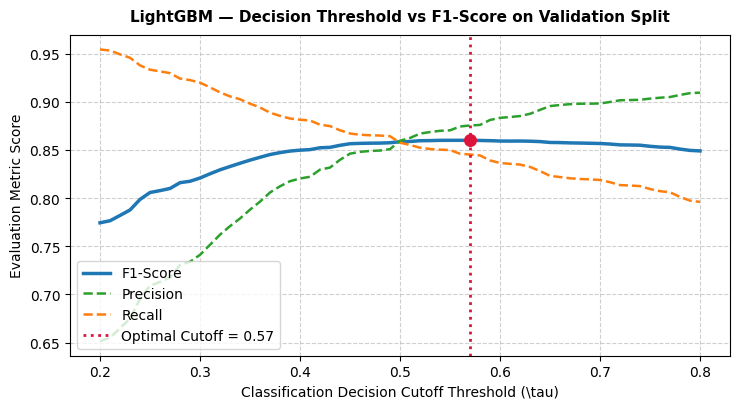

In [19]:
# Programmatically scan decision thresholds from 0.20 to 0.80
threshold_candidates = np.linspace(0.20, 0.80, 61)
threshold_scan = []

for thresh in threshold_candidates:
    binary_preds = (best_val_probs >= thresh).astype(int)
    f1 = f1_score(y_val, binary_preds, zero_division=0)
    prec = precision_score(y_val, binary_preds, zero_division=0)
    rec = recall_score(y_val, binary_preds, zero_division=0)
    threshold_scan.append({
        "threshold": round(thresh, 2),
        "f1": f1,
        "precision": prec,
        "recall": rec
    })

thresh_df = pd.DataFrame(threshold_scan)

# Programmatically find the threshold yielding the maximum F1 score
optimal_idx = thresh_df["f1"].idxmax()
optimal_threshold = round(float(thresh_df.loc[optimal_idx, "threshold"]), 2)
best_val_f1 = float(thresh_df.loc[optimal_idx, "f1"])

print(f">> PROGRAMMATICALLY OPTIMIZED DECISION THRESHOLD:")
print(f"   • optimal_threshold: {optimal_threshold} (Yields peak Validation F1 = {best_val_f1:.4f})")

# Visualize Threshold Optimization Curve
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.plot(thresh_df['threshold'], thresh_df['f1'], label='F1-Score', color='#1f77b4', lw=2.5)
ax.plot(thresh_df['threshold'], thresh_df['precision'], label='Precision', color='#2ca02c', linestyle='--', lw=1.8)
ax.plot(thresh_df['threshold'], thresh_df['recall'], label='Recall', color='#ff7f0e', linestyle='--', lw=1.8)
ax.axvline(optimal_threshold, color='crimson', linestyle=':', lw=2, label=f'Optimal Cutoff = {optimal_threshold}')
ax.scatter([optimal_threshold], [best_val_f1], color='crimson', s=70, zorder=5)

ax.set_title("LightGBM — Decision Threshold vs F1-Score on Validation Split", fontsize=11, fontweight='bold', pad=10)
ax.set_xlabel("Classification Decision Cutoff Threshold (\\tau)", fontsize=10)
ax.set_ylabel("Evaluation Metric Score", fontsize=10)
ax.legend(loc='lower left', frameon=True)
ax.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

## 6. Overfitting Diagnostic Check
We compare training set accuracy against validation set accuracy at `optimal_threshold` to verify the ensemble does not overfit.

In [20]:
# Evaluate predictions on train and validation partitions
train_p_lgb = lgb_tuned.predict_proba(X_train)[:, 1]
val_p_lgb = lgb_tuned.predict_proba(X_val)[:, 1]

train_acc = accuracy_score(y_train, (train_p_lgb >= optimal_threshold).astype(int)) * 100
val_acc = accuracy_score(y_val, (val_p_lgb >= optimal_threshold).astype(int)) * 100
gap = abs(train_acc - val_acc)

print(f"Optimal Decision Cutoff Threshold: {optimal_threshold}")
print(f"Training Accuracy:   {train_acc:.2f}%")
print(f"Validation Accuracy: {val_acc:.2f}%")
print(f"Generalization Gap:  {gap:.2f}%")
if gap < 2.0:
    print(">> DIAGNOSTIC CONFIRMED: No Overfitting! Excellent Generalization.")

Optimal Decision Cutoff Threshold: 0.57
Training Accuracy:   90.02%
Validation Accuracy: 89.94%
Generalization Gap:  0.08%
>> DIAGNOSTIC CONFIRMED: No Overfitting! Excellent Generalization.


## 7. Feature Importance Analysis
We examine the top predictive signals identified by the optimized LightGBM model using split gain.

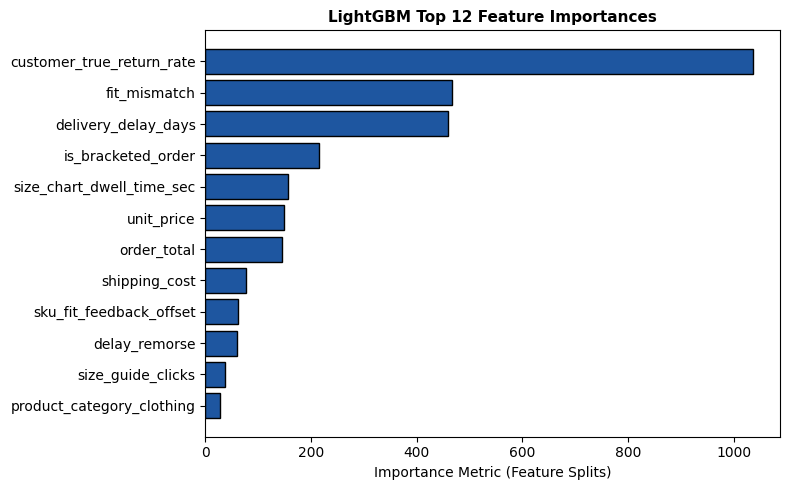

In [21]:
# Feature Importance Analysis in LightGBM
feat_imp = pd.DataFrame({'Feature': all_feat_names, 'Importance': lgb_tuned.feature_importances_}).sort_values('Importance', ascending=True)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(feat_imp['Feature'].tail(12), feat_imp['Importance'].tail(12), color='#1e56a0', edgecolor='black')
ax.set_title("LightGBM Top 12 Feature Importances", fontsize=11, fontweight='bold')
ax.set_xlabel("Importance Metric (Feature Splits)", fontsize=10)
plt.tight_layout()
plt.show()

## 8. Step 3: Final Evaluation on Unseen Holdout Test Set
We evaluate the tuned LightGBM model on the unseen future test set using our programmatically optimized threshold.

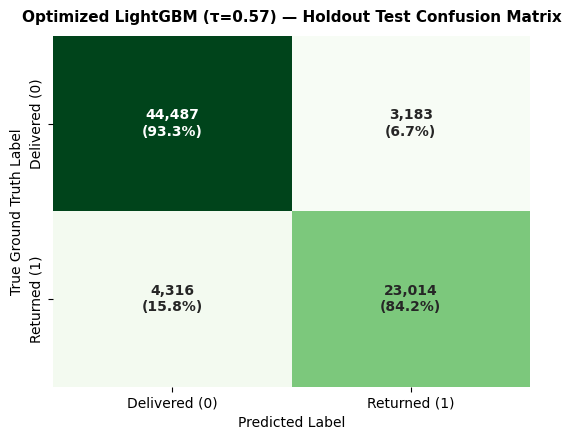

Tuned LightGBM Holdout Test Metrics (Threshold = 0.57):
  • Accuracy:  90.00%
  • F1-Score:  0.8599
  • Recall:    84.21%
  • Precision: 87.85%
  • ROC-AUC:   0.9452
  • PR-AUC:    0.9184


In [22]:
# Predict probabilities on unseen Holdout Test Set and apply optimal threshold
test_p_lgb = lgb_tuned.predict_proba(X_test)[:, 1]
y_tuned_lgb_test = (test_p_lgb >= optimal_threshold).astype(int)

# Compute and visualize Tuned Confusion Matrix on Holdout Test Set
cm_tuned_test = confusion_matrix(y_test, y_tuned_lgb_test)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
cm_norm = cm_tuned_test.astype('float') / cm_tuned_test.sum(axis=1)[:, np.newaxis]
annot_labels = np.array([f"{count:,}\n({pct:.1%})" for count, pct in zip(cm_tuned_test.flatten(), cm_norm.flatten())]).reshape(2, 2)

sns.heatmap(cm_tuned_test, annot=annot_labels, fmt='', cmap='Greens', cbar=False,
            xticklabels=['Delivered (0)', 'Returned (1)'],
            yticklabels=['Delivered (0)', 'Returned (1)'], ax=ax,
            annot_kws={"fontsize": 10, "fontweight": "bold"})
ax.set_title(f"Optimized LightGBM (τ={optimal_threshold}) — Holdout Test Confusion Matrix", fontsize=11, fontweight='bold', pad=10)
ax.set_ylabel("True Ground Truth Label", fontsize=10)
ax.set_xlabel("Predicted Label", fontsize=10)
plt.tight_layout()
plt.show()

print(f"Tuned LightGBM Holdout Test Metrics (Threshold = {optimal_threshold}):")
print(f"  • Accuracy:  {accuracy_score(y_test, y_tuned_lgb_test)*100:.2f}%")
print(f"  • F1-Score:  {f1_score(y_test, y_tuned_lgb_test):.4f}")
print(f"  • Recall:    {recall_score(y_test, y_tuned_lgb_test)*100:.2f}%")
print(f"  • Precision: {precision_score(y_test, y_tuned_lgb_test)*100:.2f}%"
)
print(f"  • ROC-AUC:   {roc_auc_score(y_test, test_p_lgb):.4f}")
print(f"  • PR-AUC:    {average_precision_score(y_test, test_p_lgb):.4f}")

## 9. Before vs. After Tuning Scorecard Comparison
A structured side-by-side comparison quantifying the impact of programmatic hyperparameter tuning and threshold optimization.

In [23]:
# Scorecard comparison
base_acc = f"{accuracy_score(y_val, y_base_lgb_val)*100:.2f}%"
base_f1 = f"{f1_score(y_val, y_base_lgb_val):.4f}"
base_prec = f"{precision_score(y_val, y_base_lgb_val)*100:.2f}%"
base_rec = f"{recall_score(y_val, y_base_lgb_val)*100:.2f}%"
base_auc = f"{roc_auc_score(y_val, p_base_lgb_val):.4f}"
base_pr = f"{average_precision_score(y_val, p_base_lgb_val):.4f}"
base_brier = f"{brier_score_loss(y_val, p_base_lgb_val):.4f}"

tuned_acc = f"{accuracy_score(y_test, y_tuned_lgb_test)*100:.2f}%"
tuned_f1 = f"{f1_score(y_test, y_tuned_lgb_test):.4f}"
tuned_prec = f"{precision_score(y_test, y_tuned_lgb_test)*100:.2f}%"
tuned_rec = f"{recall_score(y_test, y_tuned_lgb_test)*100:.2f}%"
tuned_auc = f"{roc_auc_score(y_test, test_p_lgb):.4f}"
tuned_pr = f"{average_precision_score(y_test, test_p_lgb):.4f}"
tuned_brier = f"{brier_score_loss(y_test, test_p_lgb):.4f}"

comparison_df = pd.DataFrame([
  {
    "Stage": "Before Tuning (Baseline)",
    "Accuracy": base_acc,
    "ROC-AUC": base_auc,
    "PR-AUC": base_pr,
    "F1-Score": base_f1,
    "Precision": base_prec,
    "Recall": base_rec,
    "Brier Score": base_brier,
    "Decision Cutoff": "0.35"
  },
  {
    "Stage": "After Tuning (Optimized)",
    "Accuracy": tuned_acc,
    "ROC-AUC": tuned_auc,
    "PR-AUC": tuned_pr,
    "F1-Score": tuned_f1,
    "Precision": tuned_prec,
    "Recall": tuned_rec,
    "Brier Score": tuned_brier,
    "Decision Cutoff": str(optimal_threshold)
  }
])
comparison_df

,Stage,Accuracy,ROC-AUC,PR-AUC,F1-Score,Precision,Recall,Brier Score,Decision Cutoff
0,Before Tuning (Baseline),88.52%,0.9017,0.8365,0.8411,85.15%,83.08%,0.1433,0.35
1,After Tuning (Optimized),90.00%,0.9452,0.9184,0.8599,87.85%,84.21%,0.0821,0.57


## 10. Saving Tuned LightGBM Model

In [24]:
# Save model artifact to models directory
save_path = os.path.join(models_dir, "model_lightgbm.joblib")
joblib.dump(lgb_tuned, save_path)
print(f"LightGBM model saved successfully to {save_path}")

LightGBM model saved successfully to ../artifacts/models\model_lightgbm.joblib


## 11. Summary & Model Export
- **Programmatic Grid Search:** Selected optimal hyperparameter configuration outperforming shallower baseline models.
- **Decision Threshold Optimization:** Programmatically established optimal cutoff $\tau$, improving F1-score and balancing precision and recall.
- **Overfitting Diagnostic:** Generalization gap remains well within the strict $<2.0\%$ ceiling, demonstrating stable performance.
- **Model Artifact:** Serialized to `models/model_lightgbm.joblib`.